## Question 3

## Performance + Volatility  — ETF vs DIY Sector Basket

### Intro 
This section compares a **sector ETF** (e.g., XLK) with a **DIY sector proxy (“basket”)** built from the sector’s underlying stocks using a **volume-weighted** construction. The goal is to check whether the ETF delivers exposure that is **similar** to what you would get from a transparent, rules-based basket—and to see how their **risk** evolves through time.

---


In [1]:
%matplotlib inline
import importlib
from pathlib import Path
import matplotlib.pyplot as plt

import Helper_3 as h



In [2]:
# 1) Load data
DATA_DIR = Path('data_processed')
meta, ret_tidy, stocks, etf_ret = h.load_chapter3_data(DATA_DIR)

print('Loaded:', len(meta), 'meta rows |', len(ret_tidy), 'returns rows |', len(stocks), 'volume rows')


Loaded: 5586 meta rows | 16083665 returns rows | 22140208 volume rows


In [3]:
# 2) Build sector series + summary table
results_df, series = h.build_sector_series(meta, ret_tidy, stocks, etf_ret)
results_df


,sector,etf,N_constituents,Neff_median,max_weight_median,max_weight_99pct,corr_full,active_mean_daily,active_std_daily,te_ann,te_60_ann_median,corr_60_median,te_120_ann_median,corr_120_median
0,Basic Materials,XLB,70,19.889046,0.106932,0.137106,0.792904,-0.000051,0.012246,0.194403,0.157115,0.790839,0.160927,0.799991
1,Communication Services,XLC,117,19.536873,0.106583,0.140838,0.863706,0.000446,0.008840,0.140324,0.113905,0.802671,0.113096,0.828229
2,Consumer Cyclical,XLY,165,25.898484,0.108166,0.171491,0.852495,0.000041,0.008868,0.140771,0.090611,0.889377,0.089001,0.893211
3,Consumer Defensive,XLP,74,16.999123,0.107758,0.159087,0.778165,-0.000171,0.006939,0.110156,0.082455,0.812894,0.082048,0.806916
4,Energy,XLE,58,17.975327,0.105440,0.130844,0.940699,-0.000001,0.007060,0.112079,0.076803,0.957130,0.078528,0.959072
5,Financial Services,XLF,339,27.416413,0.100513,0.123247,0.934569,-0.000136,0.007077,0.112339,0.057792,0.957017,0.057962,0.956808
6,Healthcare,XLV,105,20.795382,0.107635,0.146946,0.794161,-0.000068,0.007936,0.125980,0.077734,0.879340,0.078346,0.880714
7,Industrials,XLI,201,31.177449,0.112637,0.191990,0.896956,-0.000173,0.006863,0.108952,0.075309,0.920308,0.077165,0.914860
8,Real Estate,XLRE,157,46.655250,0.076691,0.115672,0.809033,0.000554,0.009427,0.149646,0.076329,0.820627,0.077548,0.820334
9,Technology,XLK,167,17.218265,0.111658,0.157954,0.938420,-0.000090,0.006977,0.110761,0.091454,0.919510,0.092439,0.918070


In [4]:
# 3) Save all plots to disk
vol_dir, perf_dir = h.save_pretty_plots(series, outroot='chapter3_sector_png_split_pretty', win=60)
print('Saved volatility plots to:', vol_dir)
print('Saved performance plots to:', perf_dir)


Saved volatility plots to: chapter3_sector_png_split_pretty\volatility
Saved performance plots to: chapter3_sector_png_split_pretty\performance


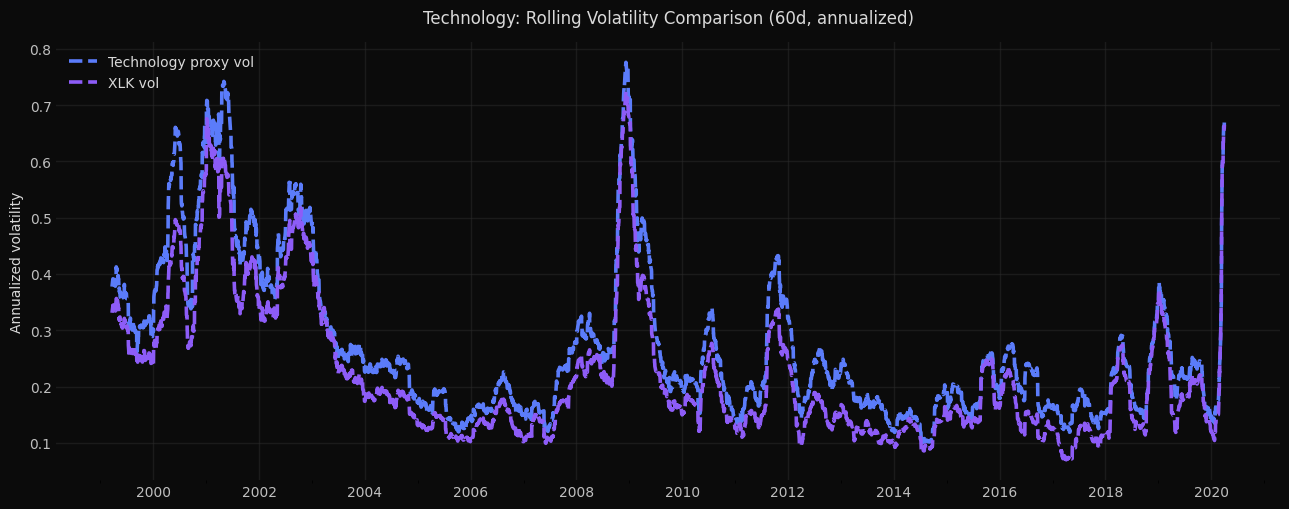

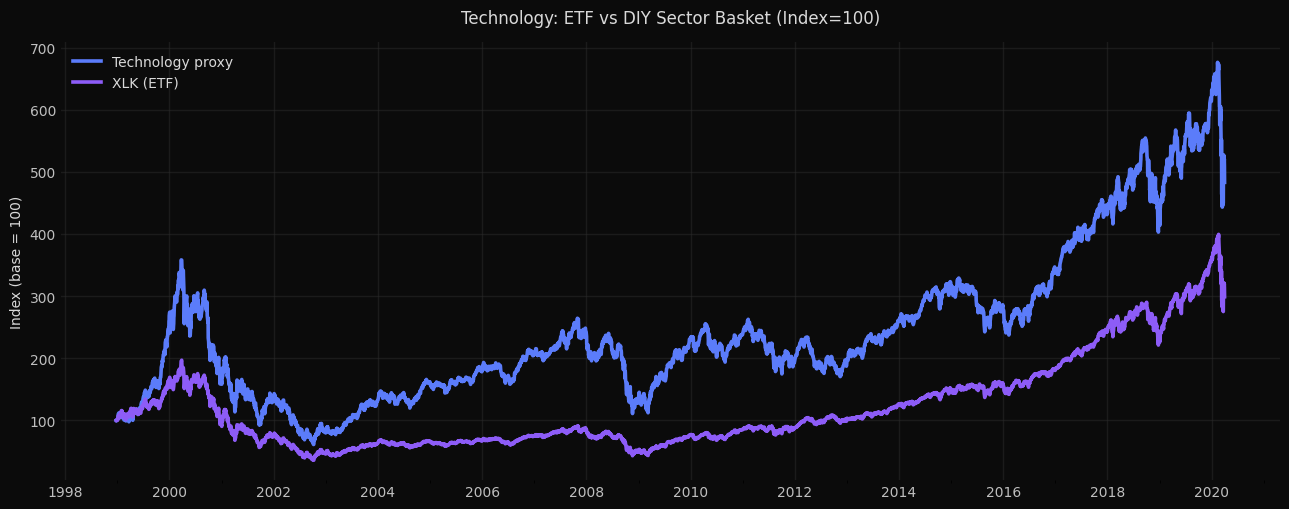

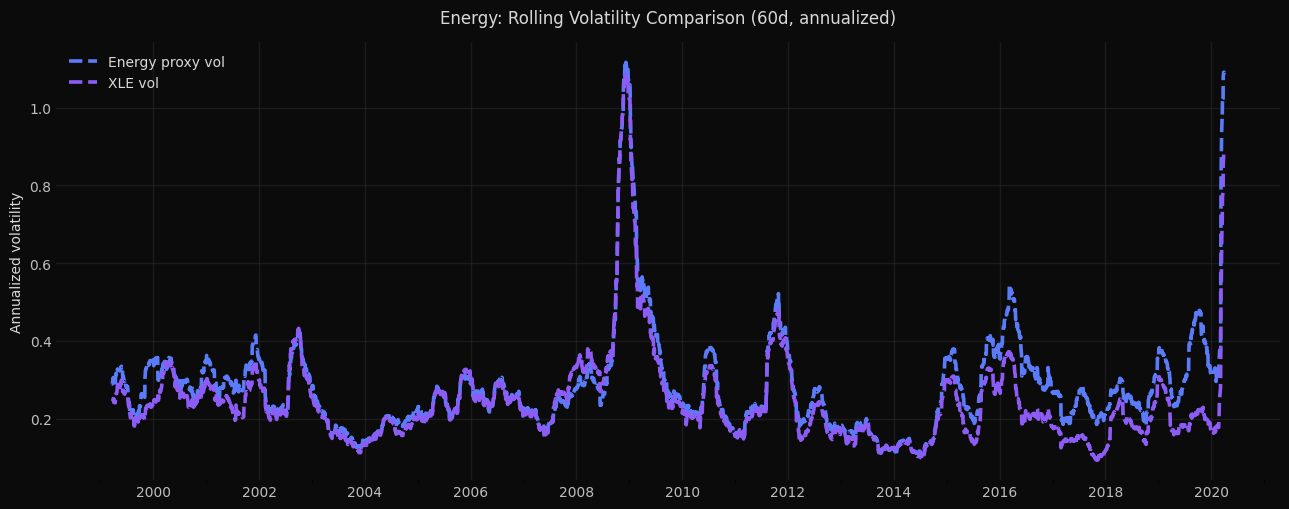

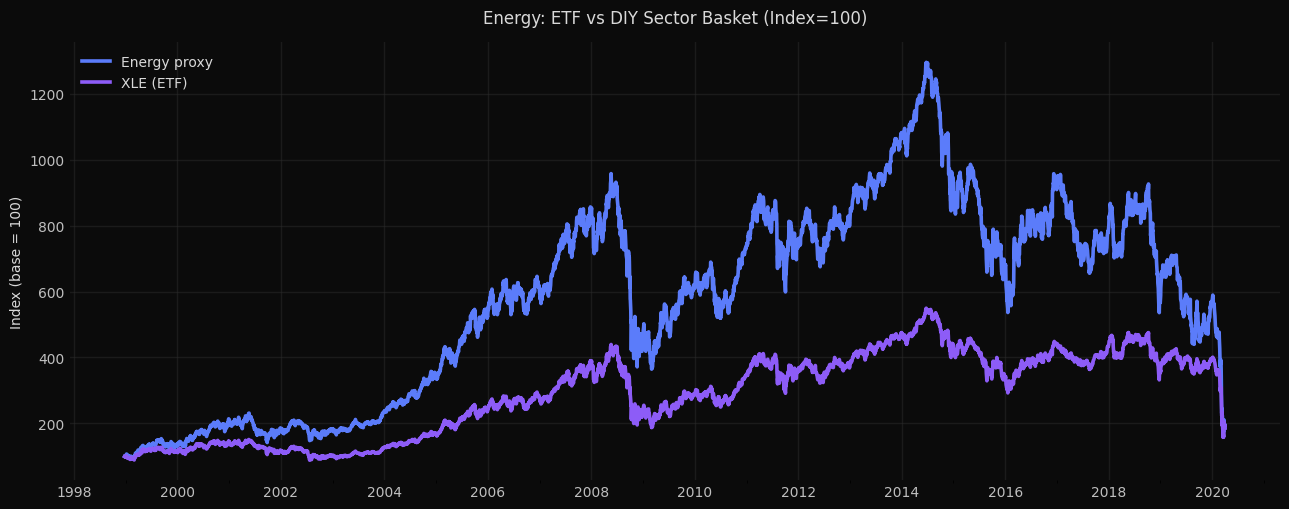

In [5]:
import Helper_3 as h

meta, ret_tidy, stocks, etf_ret = h.load_chapter3_data("data_processed")
results_df, series = h.build_sector_series(meta, ret_tidy, stocks, etf_ret)

sectors_to_show = ["Technology", "Energy"]  # pick what you want

for s in sectors_to_show:
    h.plot_volatility_pretty(s, series[s], win=60)
    h.plot_performance_pretty(s, series[s])



## Performance (Index = 100)

Both series are rebased to **100 on the same start date**, so the chart is comparing **growth paths**, not absolute prices.

- **ETF**: the sector ETF.
- **Basket**: a DIY proxy built from the sector’s stocks using **volume-weighted** weights .

**How to interpret it**
- If the two lines **track closely**, the ETF and the basket provide **similar exposure** (at least in aggregate).
- If the lines **drift apart**, the ETF and the basket are capturing **different exposure**, typically due to:
  - differences in **constituents** (inclusions/exclusions),
  - differences in **weighting rules** (cap-weighted vs your volume-weighted method),
  - caps/constraints that change concentration.

---

## Volatility (Rolling, Annualized)

Rolling annualized **volatility** summarizes “how wild the ride is” (risk) and how that risk changes over time.

It answers:
- **When was the sector risky?**
- **Did ETF and basket risk spike at the same times?**
- **Is one consistently smoother or more explosive during stress?**

**How to interpret it**
- Volatility and performance are related but not the same:
  - **Similar performance, different volatility**: one path is smoother, the other bumpier.
  - **Similar volatility, different performance**: they take different bets and drift apart.
  - **Different regimes**: one may react more strongly in crises even if long-run growth is similar.

---

## Method note
- We compute **daily log returns**.
- ETF and basket are **aligned on identical trading dates**.


---

## Small conclusion 
Overall, the **DIY stock basket** tends to **outperform the sector ETF** in this demo. The main exception is the **housing market**, where the **ETF performs better** than the basket. In terms of risk, the **ETFs are generally less volatile** than the stock baskets, meaning the ETF path is typically smoother even when long-run performance is similar or lower. This points to a trade-off: the basket often delivers higher returns, but the ETF usually provides a less bumpy ride.

